# TP N°1 – EDA del dataset DataCo Smart Supply Chain
Objetivo: analizar cuántos pedidos llegan tarde, qué factores se asocian con esas demoras y cómo se relacionan con la rentabilidad.
Dataset: DataCo Smart Supply Chain (180.519 ítems de pedido, 65.752 pedidos)

### Dependencias

In [1]:
import numpy as np ##Importacion de librerias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Lectura e integridad

In [2]:
df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin-1")  ##Lectura y almacenamiento del archivo en un dataframe


In [3]:
df.shape

(180519, 53)

In [4]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [5]:
df.tail()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class
180518,PAYMENT,4,4,168.949997,383.980011,Shipping on time,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 18:54,Standard Class


In [6]:
df.info() ## Revisa si hay datos nulos

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [7]:
df = df.drop(columns=["Product Description", "Order Zipcode", "Product Image","Product Card Id","Latitude", "Longitude","Customer Email", "Customer Fname", "Customer Lname","Customer Password","Category Id","Department Id","Order Profit Per Order","Order Customer Id","Order Item Cardprod Id",])   ## Elimino aglunas columnas con nulos ,y las que no van a ser relevantes para el analisis.
print(df.shape)

(180519, 38)


In [8]:
df["Order Item Id"].nunique() ## Compruebo duplicados

180519

In [9]:
df["Delivery Status"].unique()

<ArrowStringArray>
['Advance shipping', 'Late delivery', 'Shipping on time', 'Shipping canceled']
Length: 4, dtype: str

In [10]:
df["Shipping Mode"].unique()

<ArrowStringArray>
['Standard Class', 'First Class', 'Second Class', 'Same Day']
Length: 4, dtype: str

In [11]:
df["Market"].unique()

<ArrowStringArray>
['Pacific Asia', 'USCA', 'Africa', 'Europe', 'LATAM']
Length: 5, dtype: str

In [12]:
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Customer Id,Customer Zipcode,Order Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Product Category Id,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,6691.379495,35921.126914,36221.894903,20.664741,0.101668,90260.000000,141.232550,0.120647,2.127638,203.772096,183.107609,31.851451,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,4162.918106,37542.461122,21045.379569,21.800901,0.070415,52111.490959,139.732492,0.466796,1.453451,132.273077,120.043670,15.640064,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,1.000000,603.000000,1.000000,0.000000,0.000000,1.000000,9.990000,-2.750000,1.000000,9.990000,7.490000,2.000000,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,3258.500000,725.000000,18057.000000,5.400000,0.040000,45130.500000,50.000000,0.080000,1.000000,119.980003,104.379997,18.000000,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,6457.000000,19380.000000,36140.000000,14.000000,0.100000,90260.000000,59.990002,0.270000,1.000000,199.919998,163.990005,29.000000,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,9779.000000,78207.000000,54144.000000,29.990000,0.160000,135389.500000,199.990005,0.360000,3.000000,299.950012,247.399994,45.000000,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,20757.000000,99205.000000,77204.000000,500.000000,0.250000,180519.000000,1999.989990,0.500000,5.000000,1999.989990,1939.989990,76.000000,1999.989990,0.0


In [13]:
# Convierte order date a formato fecha
df["order date (DateOrders)"] = pd.to_datetime(df["order date (DateOrders)"])


In [14]:
pedidos = df.drop_duplicates(subset="Order Id").copy() ##Como cada fila es un ítem y un pedido puede tener varios, usé drop_duplicates por Order Id para analizar pedidos completos.

### EDA

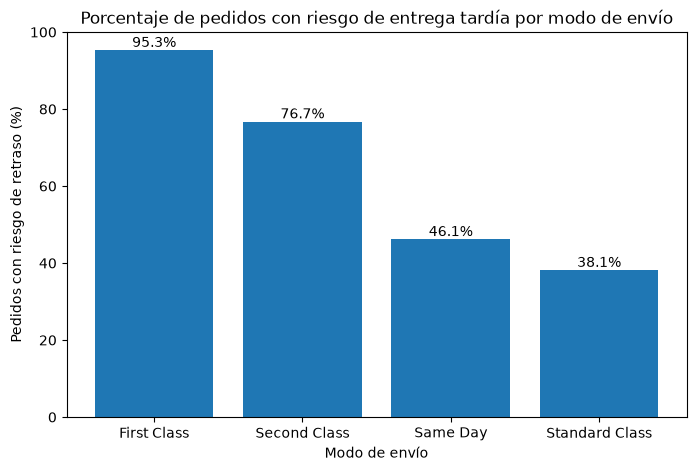

In [15]:
##Agrupa los pedidos por modo de envío y calcula el promedio de la variable Late_delivery_risk, que vale 0 o 1. Ese promedio es la proporción de pedidos con riesgo de retraso, que multipliqué por 100 para expresarla en porcentaje.

tardias = (pedidos.groupby("Shipping Mode")["Late_delivery_risk"].mean() * 100).sort_values(ascending=False) 
plt.figure(figsize=(8, 5))
barras = plt.bar(tardias.index, tardias.values)
plt.bar_label(barras, fmt="%.1f%%")
plt.title("Porcentaje de pedidos con riesgo de entrega tardía por modo de envío")
plt.xlabel("Modo de envío")
plt.ylabel("Pedidos con riesgo de retraso (%)")
plt.ylim(0, 100)
plt.show()

## El modo de envio si influye en las demoras, pero no porque sean mas lentos sino porque los tiempos prometidos son menores de lo que se puede cumplir ,lo que genera entregas tardias.Por ejemplo, first class promete que los pedidos van a llegar en un dia, pero tardan 2 el 95% de las veces como muestra el grafico mas arriba.

In [16]:
pedidos.groupby("Shipping Mode")[["Days for shipment (scheduled)", "Days for shipping (real)"]].mean().round(2)


,Days for shipment (scheduled),Days for shipping (real)
Shipping Mode,,
First Class,1.0,2.00
Same Day,0.0,0.48
Second Class,2.0,4.00
Standard Class,4.0,4.00


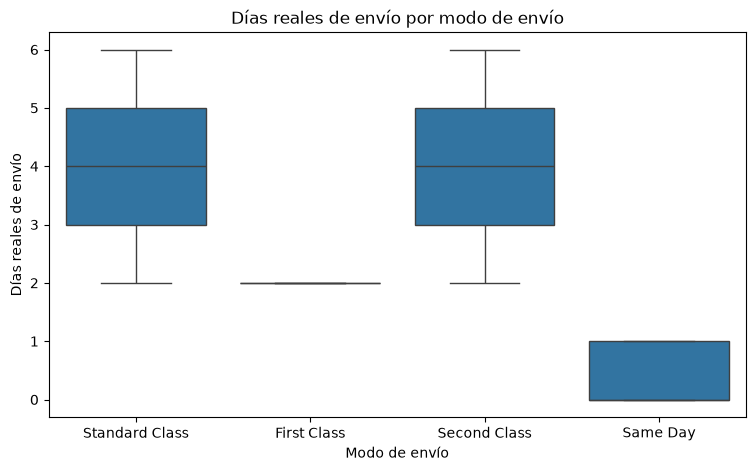

In [17]:
plt.figure(figsize=(9, 5))
sns.boxplot(x="Shipping Mode", y="Days for shipping (real)", data=pedidos)
plt.title("Días reales de envío por modo de envío")
plt.xlabel("Modo de envío")
plt.ylabel("Días reales de envío")
plt.show()

## El grafico muestra que Standard Class y Second Class tienen la misma distribucion de dias reales. En first class casi todos los pedidos tardan 2 dias, por eso la caja se ve como una linea. Y los envios Same Day , llegan entre 0 y 1 dia.

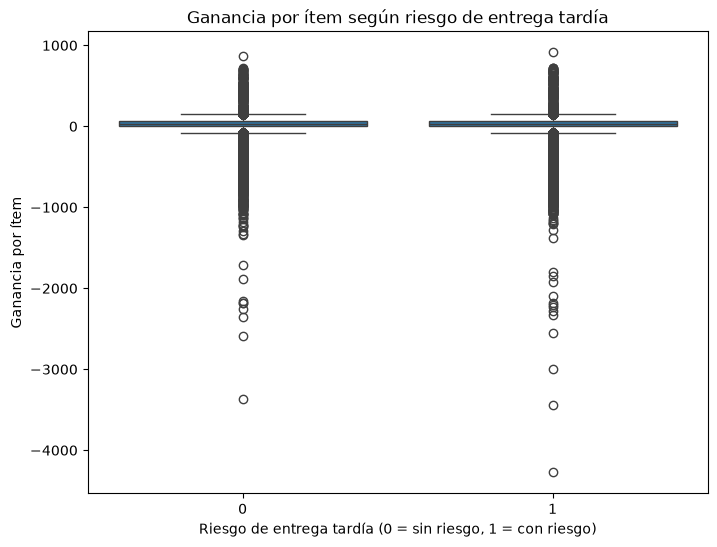

In [18]:
plt.figure(figsize=(8, 6))
sns.boxplot(x="Late_delivery_risk", y="Benefit per order", data=df)
plt.title("Ganancia por ítem según riesgo de entrega tardía")
plt.xlabel("Riesgo de entrega tardía (0 = sin riesgo, 1 = con riesgo)")
plt.ylabel("Ganancia por ítem")
plt.show()

 ## El grafico muestra que no hay gran diferencia de ganancia segun el riesgo de entrega tardia, son casi iguales. Hay muchos puntos atipicos, mas negativos que positivos.

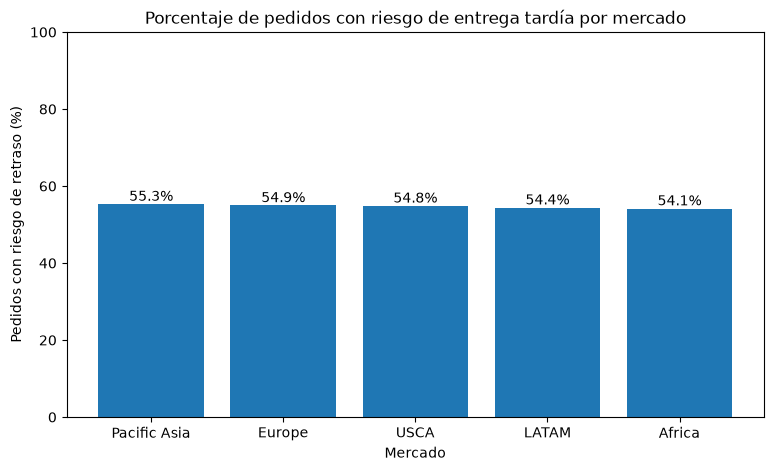

In [19]:
##Se asemeja al grafico de los modos de envio, pero esta vez los agrupe por region.
##Se puede ver claramente que la region no es un factor decisivo a la hora de que el pedido tenga retraso o no, como si lo es el modo de envio.

tardias_mercado = (pedidos.groupby("Market")["Late_delivery_risk"].mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(9, 5))
barras = plt.bar(tardias_mercado.index, tardias_mercado.values)
plt.bar_label(barras, fmt="%.1f%%")
plt.title("Porcentaje de pedidos con riesgo de entrega tardía por mercado")
plt.xlabel("Mercado")
plt.ylabel("Pedidos con riesgo de retraso (%)")
plt.ylim(0, 100)
plt.show()

## Se asemeja al grafico de los modos de envio, pero esta vez los agrupe por mercado.
## Se puede ver claramente que la region no es un factor decisivo a la hora de que el pedido tenga retraso o no, como si lo es el modo de envio,los mercados van de 54,1% a 55,3%, mientras que por modo de envío iba de 38,1% a 95,3%.]
 

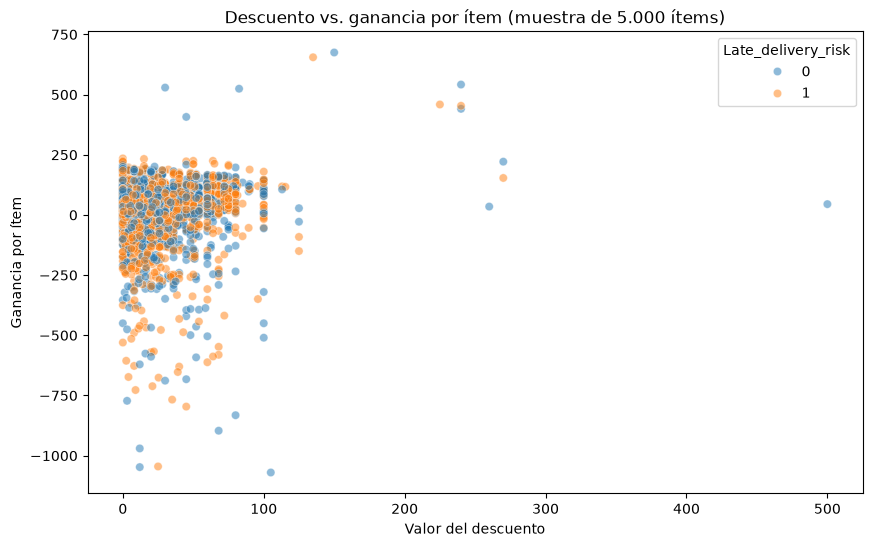

In [20]:
muestra = df.sample(5000, random_state=42)  
plt.figure(figsize=(10, 6))
sns.scatterplot(data=muestra, x="Order Item Discount", y="Benefit per order",
                hue="Late_delivery_risk", alpha=0.5)
plt.title("Descuento vs. ganancia por ítem (muestra de 5.000 ítems)")
plt.xlabel("Valor del descuento")
plt.ylabel("Ganancia por ítem")
plt.show()

## El gráfico (muestra de 5.000 ítems) no muestra una relación clara entre el valor del descuento y la ganancia por ítem. La mayoría de los ítems tiene descuentos de hasta 100, y en todo ese tramo la ganancia se reparte de forma similar, entre aproximadamente -250 y 250.

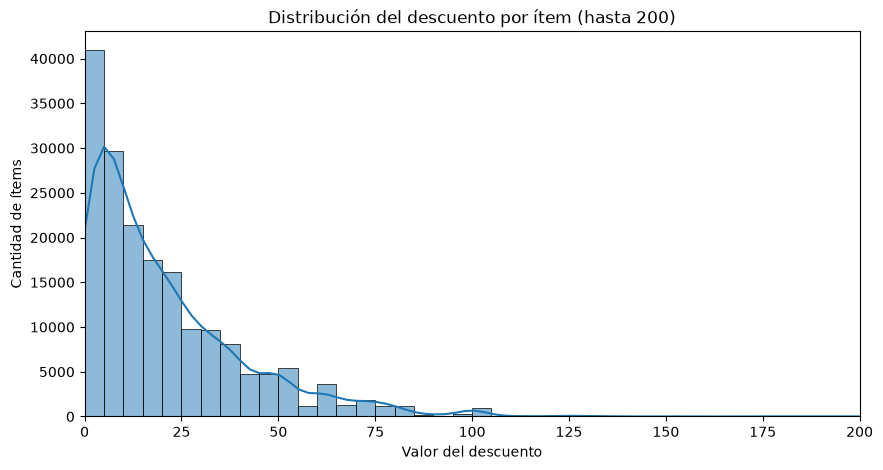

Ítems con descuento mayor a 200: 158


In [21]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Order Item Discount"], kde=True, bins=range(0, 201, 5), kde_kws={"bw_adjust": 2})
plt.xlim(0, 200)   
plt.title("Distribución del descuento por ítem (hasta 200)")
plt.xlabel("Valor del descuento")
plt.ylabel("Cantidad de ítems")
plt.show()
print("Ítems con descuento mayor a 200:", (df["Order Item Discount"] > 200).sum()) ## Muestra los items que quedaron fuera del grafico

In [22]:
df.groupby("Late_delivery_risk")["Order Item Discount"].mean().round(2)

Late_delivery_risk
0    20.68
1    20.65
Name: Order Item Discount, dtype: float64

## El grafico muestra que la mayoria de los items tienen un descuento bajo. Con el groupby se puede ver que en promedio el descuento en items con o sin riesgo de retraso es similar, asi que no se asocia a las demoras.

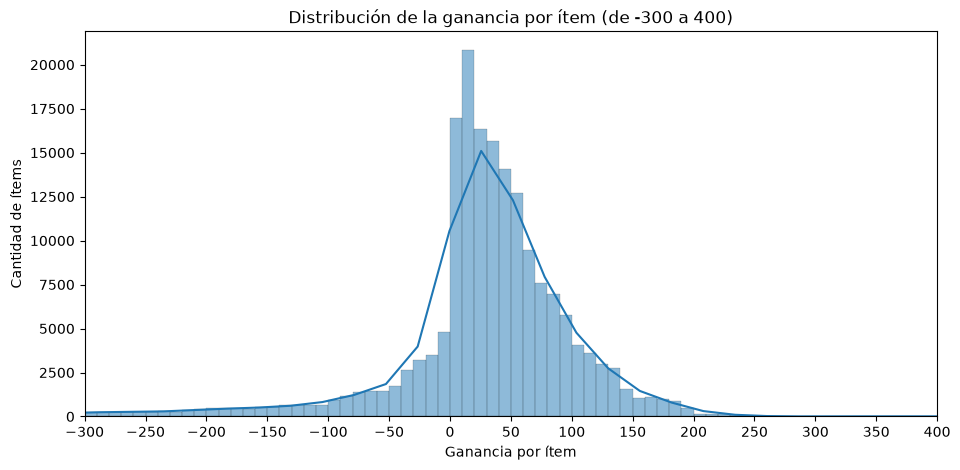

Ítems fuera del rango mostrado: 3362
Porcentaje de ítems con pérdida: 18.7 %


In [23]:
plt.figure(figsize=(11, 5))
sns.histplot(df["Benefit per order"], kde=True, bins=range(-300, 401, 10), kde_kws={"bw_adjust": 2})
plt.xlim(-300, 400)   
plt.xticks(range(-300, 401, 50))
plt.title("Distribución de la ganancia por ítem (de -300 a 400)")
plt.xlabel("Ganancia por ítem")
plt.ylabel("Cantidad de ítems")
plt.show()
print("Ítems fuera del rango mostrado:", ((df["Benefit per order"] < -300) | (df["Benefit per order"] > 400)).sum())
print("Porcentaje de ítems con pérdida:", round((df["Benefit per order"] < 0).mean() * 100, 1), "%")

## El grafico muestra los items que van desde -300 de perdida hasta 400 de ganancia y muestra que la mayor parte de la ganancia por item esta entre 0 y 65 aproximadamente.La distribución es asimétrica, con una cola hacia pérdidas grandes.

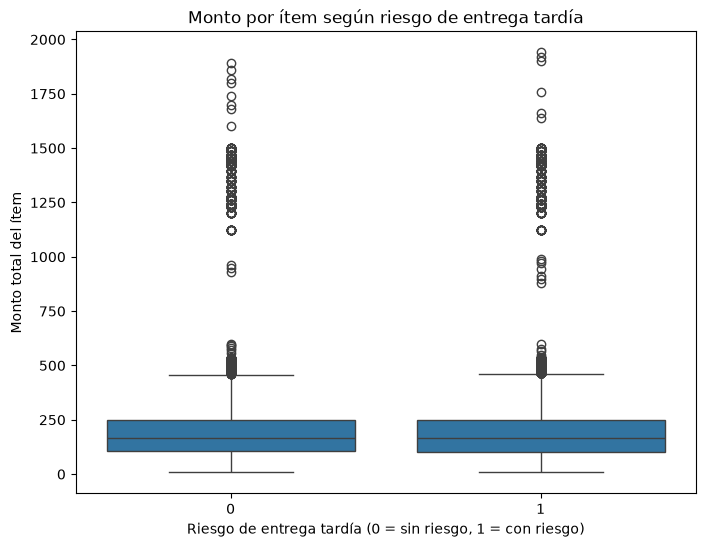

In [24]:
plt.figure(figsize=(8, 6))
sns.boxplot(x="Late_delivery_risk", y="Order Item Total", data=df)
plt.title("Monto por ítem según riesgo de entrega tardía")
plt.xlabel("Riesgo de entrega tardía (0 = sin riesgo, 1 = con riesgo)")
plt.ylabel("Monto total del ítem")
plt.show()

## La distribución del monto por ítem es prácticamente idéntica en los ítems con y sin riesgo de entrega tardía. La mediana es la misma en ambos grupos y la media es muy parecida.En ambos grupos aparecen valores atípicos de montos altos, desde aproximadamente 470 hasta cerca de 1.900. Esto indica que el monto del ítem no se asocia al riesgo de entrega tardía.

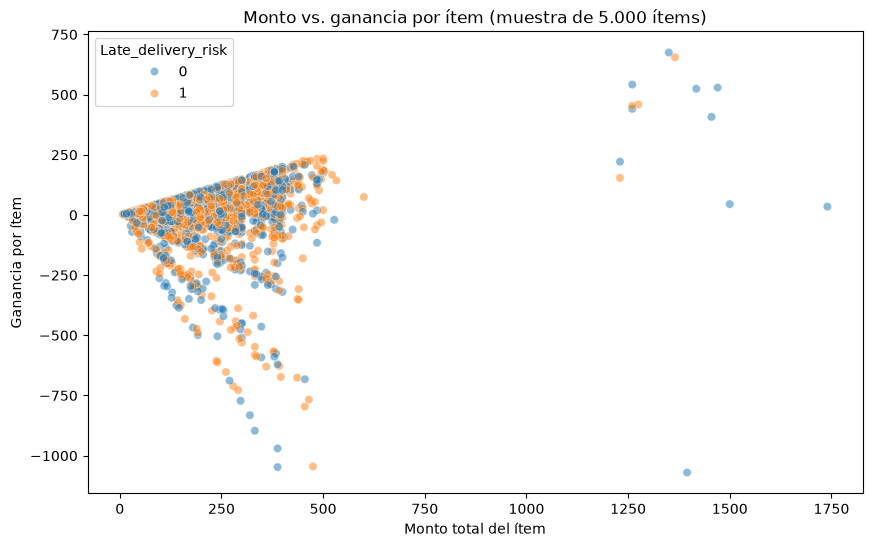

In [25]:
muestra = df.sample(5000, random_state=42)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=muestra, x="Order Item Total", y="Benefit per order",
                hue="Late_delivery_risk", alpha=0.5)
plt.title("Monto vs. ganancia por ítem (muestra de 5.000 ítems)")
plt.xlabel("Monto total del ítem")
plt.ylabel("Ganancia por ítem")
plt.show()


## El grafico muestra que, en general, a mayor monto total del item, la ganancia tiende a ser mayor tambien.Los ítems con y sin riesgo de entrega tardía se distribuyen de forma similar

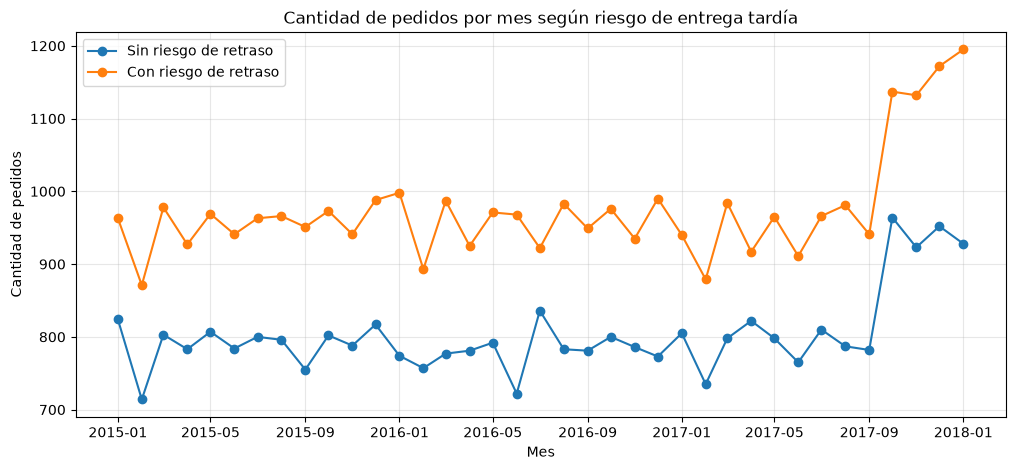

In [26]:
# Mes de cada pedido
pedidos["mes"] = pedidos["order date (DateOrders)"].dt.to_period("M").dt.to_timestamp()

# Pedidos por mes y por riesgo de retraso (una columna por cada valor de 0 y 1)
tabla = pedidos.groupby(["mes", "Late_delivery_risk"]).size().unstack()
tabla = tabla.rename(columns={0: "Sin riesgo de retraso", 1: "Con riesgo de retraso"})

plt.figure(figsize=(12, 5))
plt.plot(tabla.index, tabla["Sin riesgo de retraso"], marker="o", label="Sin riesgo de retraso")
plt.plot(tabla.index, tabla["Con riesgo de retraso"], marker="o", label="Con riesgo de retraso")
plt.title("Cantidad de pedidos por mes según riesgo de entrega tardía")
plt.xlabel("Mes")
plt.ylabel("Cantidad de pedidos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## En todos los meses analizados hay más pedidos con riesgo de retraso que sin riesgo

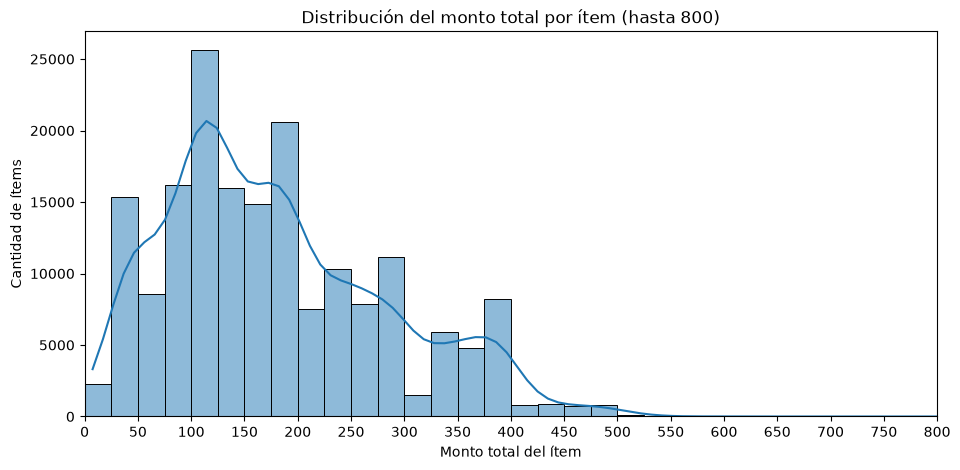

Ítems con monto mayor a 800: 467


In [27]:
plt.figure(figsize=(11, 5))
sns.histplot(df["Order Item Total"], kde=True, bins=range(0, 2001, 25), kde_kws={"bw_adjust": 2})
plt.xlim(0, 800)                  # se acota el eje; los montos mayores son muy pocos
plt.xticks(range(0, 801, 50))  
plt.title("Distribución del monto total por ítem (hasta 800)")
plt.xlabel("Monto total del ítem")
plt.ylabel("Cantidad de ítems")
plt.show()
print("Ítems con monto mayor a 800:", (df["Order Item Total"] > 800).sum())

## La mayoría de los ítems tiene montos bajos o medios con un pico entre 100 y 125, y la cantidad de ítems cae a medida que el monto aumenta. Grafique hasta 800 para que sea mas facil leer el grafico.

In [28]:
print("% de pedidos con riesgo de retraso:", round(pedidos["Late_delivery_risk"].mean() * 100, 1)) ## Calcula el porcentaje de pedidos con riesgo de retraso

% de pedidos con riesgo de retraso: 54.8


In [29]:
print(pedidos["Delivery Status"].value_counts(normalize=True).mul(100).round(1)) ## Muestra el porcentaje de pedidos que hay en cada estado de entrega

Delivery Status
Late delivery        54.8
Advance shipping     23.0
Shipping on time     17.8
Shipping canceled     4.3
Name: proportion, dtype: float64


In [30]:
print(pedidos.groupby("Shipping Mode")[["Days for shipment (scheduled)", "Days for shipping (real)"]].mean().round(2)) ## Muestra para cada tipo de envio el promedio de los dias estipulados y el de los dias que en realidad tardan en llegar los pedidos.

                Days for shipment (scheduled)  Days for shipping (real)
Shipping Mode                                                          
First Class                               1.0                      2.00
Same Day                                  0.0                      0.48
Second Class                              2.0                      4.00
Standard Class                            4.0                      4.00


In [31]:
print("% de ítems con pérdida:", round((df["Benefit per order"] < 0).mean() * 100, 1)) ## Muestra que porcentaje de los items genera perdida

% de ítems con pérdida: 18.7
